# Trabajo Final: Evaluación del Impacto de El Niño Costero (2017) en la Provincia de Trujillo mediante Geocomputación
**Curso:** Geocomputación (1GEO20) - PUCP, 2026-II  
Integrantes:
Javier Esparza (20211181) Jimena Tamariz (20190091)

## Descripción General
El presente proyecto aplica flujos de geocómputo en Python para evaluar la relación entre las precipitaciones diarias extremas y la extensión de las áreas afectadas por inundaciones en la provincia de Trujillo (La Libertad) durante el evento extraordinario de El Niño Costero de 2017.

El trabajo integra la comparación de dos fuentes independientes de precipitación (PISCOp_d v3.0 de SENAMHI y NASA GPM IMERG) y el procesamiento de imágenes de radar SAR (Sentinel-1 RTC) para delimitar las superficies inundadas.
* **Área de estudio:** Provincia de Trujillo, departamento de La Libertad, Perú.
* **Periodo temporal de análisis:** 01 de febrero de 2017 al 30 de abril de 2017.
* **Variables analizadas:** Precipitación diaria acumulada (mm/día) y Coeficiente de retrodifusión SAR / Superficie afectada (\\(dB\\), bandas VV/VH).

### Objetivo General
Evaluar la relación entre los eventos de precipitación extrema y la extensión de las áreas afectadas por inundaciones en la provincia de Trujillo durante El Niño Costero de 2017, integrando la comparación estadística de dos fuentes de lluvia (PISCOp_d v3.0 e IMERG) y el procesamiento de imágenes de radar Sentinel-1 RTC mediante flujos de geocómputo reproducibles en Python

## Repositorios y Fuentes de Datos
**Datos crudos (Drive):** https://drive.google.com/drive/folders/16QF3B51roLMAUaSuz5pNHf8uCbjVEluh?usp=sharing

**Repositorio (GitHub):** [ENLACE Al REPOSITORIO DE GITHUB]

**Fuentes utilizadas (Modelos y formatos):**
1. **Sentinel-1 RTC (Copernicus / ESA):**
   * *Formato:* Cloud Optimized GeoTIFF (COG).
   * *Acceso:* Consulta remota vía API STAC en Microsoft Planetary Computer.
2. **PISCOp_d v3.0 (SENAMHI):**
   * *Formato:* NetCDF multidimensional (`.nc`).
   * *Acceso:* Descarga directa alojada en Google Drive.
3. **NASA GPM IMERG Final Run v06:**
   * *Formato:* NetCDF de series de tiempo (`.nc`) .
   * *Acceso:* Exportación desde NASA Giovanni / GES-DISC y almacenamiento en Drive .


## Justificación del Uso de IA
Se utilizó IA como asistencia técnica para adaptar funciones vistas en clase (ej. renombrado de dimensiones temporales en `xarray` para PISCO), optimizar la alineación espacial (EPSG:4326) y documentar limitaciones de la huella orbital del radar. No se delegó el análisis crítico ni la selección de variables.

**1. Exploración preliminar de la superficie afectada mediante imágenes de radar Sentinel-1 RTC: comparación antes y después de El Niño Costero (2017).**

In [5]:
# Instalación de la librería de de Google Earth Engine
!pip install -q earthengine-api
import ee

# Autenticación la cuenta de Google para permitir el acceso a Earth Engine
ee.Authenticate(auth_mode='notebook')# Autenticación

# 3. Inicialización usando tu Project ID
PROJECT_ID = 'kobiprojecto'  # Reemplaza con tu Project ID exacto
ee.Initialize(project=PROJECT_ID)

# 4. Prueba de conexión
print("Conexión exitosa:", ee.String("Google Earth Engine activo").getInfo())

Conexión exitosa: Google Earth Engine activo


In [6]:
# Instalación de las librerías necesarias para STAC y Planetary Computer
!pip install -q planetary_computer pystac_client rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 7.9 MB/s eta 0:00:00


In [7]:
#Importación de librerías
import warnings # Librería estándar de Python.
import gdown # Para descargar archivos de Google Drive.
import geopandas as gpd # Para manejar datos vectoriales (shapefiles).
import planetary_computer # Para firmar el acceso al catálogo de Microsoft.
import pystac_client # Para conectarse al catálogo STAC.
import rioxarray # Para leer y recortar rásters en la nube.
import matplotlib.pyplot as plt # Para generar los gráficos.

warnings.filterwarnings('ignore') # Oculta advertencias en consola.

In [8]:
#Descarga y lectura del polígono de Trujillo

id_archivo = "1TOlTNLJS4vpC11m2tFysRtXv80RTj_c4"
gdown.download(id=id_archivo, output="trujillo.zip", quiet=False)

# AYUDA IA: Agregamos '.to_crs("EPSG:4326")' a la lectura del shapefile.
# Esto asegura que el vector esté en grados (lon/lat) para que empate con el mapa satelital.

gdf_trujillo = gpd.read_file('zip://trujillo.zip').to_crs("EPSG:4326")
BBOX = list(gdf_trujillo.total_bounds)

Downloading...
From: https://drive.google.com/uc?id=1TOlTNLJS4vpC11m2tFysRtXv80RTj_c4
To: /content/trujillo.zip
100%|██████████| 27.4k/27.4k [00:00<00:00, 26.3MB/s]


In [9]:
#Conexión al catálogo de imágenes satelitales
catalogo = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

In [10]:
#Función para leer y recortar las imágenes de radar

# ADAPTACIÓN IA: 'overview_level=2' descarga una vista previa del COG a menor resolución para que Colab no demore.
# ADAPTACIÓN IA: Cambiamos '.clip_box()' por '.clip(gdf.geometry)' para recortar con la silueta irregular de la provincia.
# ADAPTACIÓN IA: 'reproject' fuerza al ráster a pasarse a grados (EPSG:4326) para alinearse con el vector rojo.

def leer_y_recortar_radar(item, clave, gdf):
    da = (rioxarray.open_rasterio( item.assets[clave].href, masked=True, overview_level=2)
        .squeeze("band", drop=True) # Elimina dimensiones innecesarias
        .rio.clip(gdf.geometry.values, gdf.crs)
        .rio.reproject("EPSG:4326")
        .load())
    return da

In [13]:
#Función para seleccionar la mejor escena por periodo
# Con apoyo de IA, se modificó la función original para limitar el número de escenas procesadas y reducir las solicitudes al
# catálogo de Microsoft Planetary Computer, ante el error de límite de consultas (rate limit).

import time

def obtener_mejor_escena(rango_fechas):
    try:
        items = catalogo.search(collections=["sentinel-1-rtc"], bbox=BBOX, datetime=rango_fechas, max_items=5).item_collection()

    except Exception as e:
        print("Error al consultar el catálogo:", e)
        return None, None

    mejor_vv = None
    escena_valida = None
    max_pixeles = 0

    for item in items:
        try:
            escena = planetary_computer.sign(item)

            vv_temp = leer_y_recortar_radar(escena, "vv", gdf_trujillo )

            pixeles_validos = int((vv_temp > 0).sum().item())
            # ADAPTACIÓN IA: Contamos matemáticamente los píxeles reales (>0) para ignorar los bordes vacíos del radar.

            print("Escena:", escena.datetime.date(), "| Píxeles válidos:", pixeles_validos )

            if pixeles_validos > max_pixeles:
                max_pixeles = pixeles_validos
                mejor_vv = vv_temp
                escena_valida = escena

            time.sleep(2)

        except Exception as e:
            print("No se pudo procesar una escena:", e)
            time.sleep(5)

    return mejor_vv, escena_valida

# LIMITACIÓN IDENTIFICADA: Al seleccionar una sola escena, se generan cortes
# por el borde del barrido satelital. Como trabajo futuro, se fusionarán
# imágenes (mosaico) para obtener el 100% de datos en el área de estudio.

In [14]:
#Búsqueda de imágenes antes y después de El Niño Costero

#Con apoyo de IA, se incorporaron pausas entre las búsquedas para reducir la frecuencia de solicitudes al catálogo y
#disminuir la probabilidad de alcanzar el límite de consultas.

import time

print("Buscando la mejor imagen antes del evento...")

vv_antes, escena_antes = obtener_mejor_escena("2017-02-01/2017-02-28")

time.sleep(10)

print("\nBuscando la mejor imagen después del inicio del evento...")

vv_despues, escena_despues = obtener_mejor_escena("2017-03-15/2017-04-30")

if vv_antes is not None:
    print("Fecha anterior:", escena_antes.datetime.date())

if vv_despues is not None:
    print("Fecha posterior:", escena_despues.datetime.date())


Buscando la mejor imagen antes del evento...
Escena: 2017-02-27 | Píxeles válidos: 227791
Escena: 2017-02-22 | Píxeles válidos: 114399
Escena: 2017-02-22 | Píxeles válidos: 139437
Escena: 2017-02-10 | Píxeles válidos: 117111
Escena: 2017-02-10 | Píxeles válidos: 140951

Buscando la mejor imagen después del inicio del evento...
Escena: 2017-04-28 | Píxeles válidos: 227423
Escena: 2017-04-23 | Píxeles válidos: 114751
Escena: 2017-04-23 | Píxeles válidos: 139576
Escena: 2017-04-20 | Píxeles válidos: 89664
Escena: 2017-04-20 | Píxeles válidos: 189073
Fecha anterior: 2017-02-27
Fecha posterior: 2017-04-28


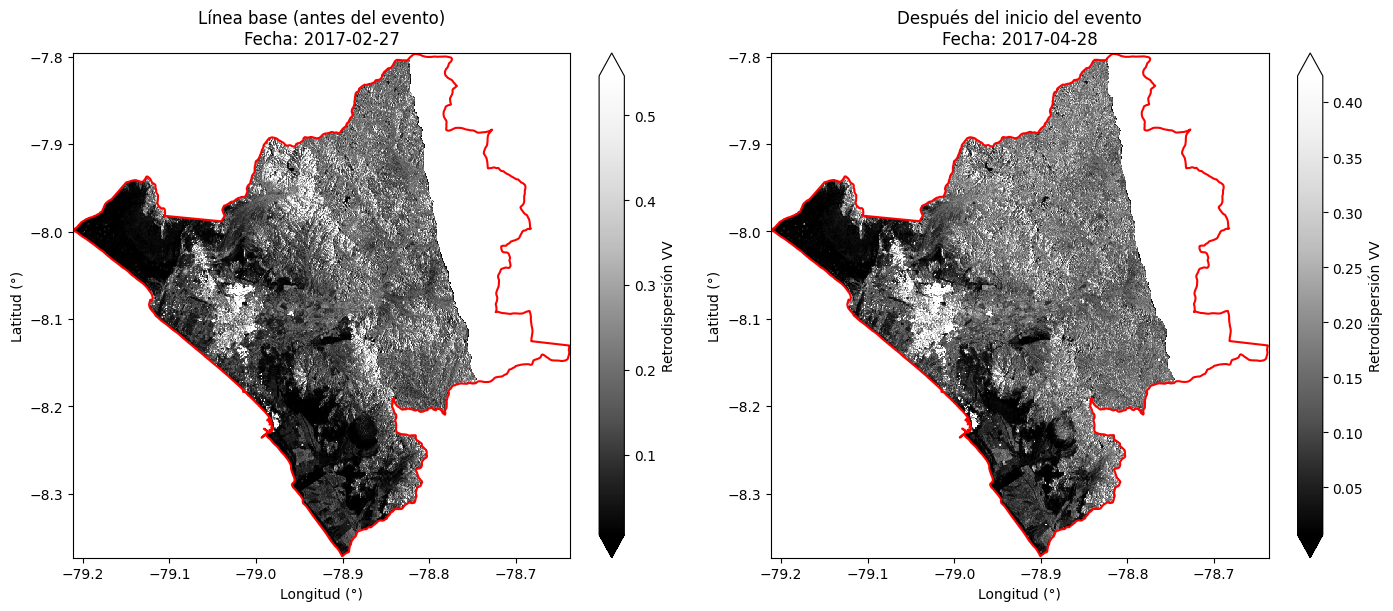

In [15]:
#LIMITACIÓN IDENTIFICADA:
#Se selecciona una sola escena por periodo, por lo que podría haber zonas de la provincia sin cobertura si la escena no abarca todo el territorio.
#Como trabajo futuro, se evaluará la combinación de varias escenas mediante un mosaico para mejorar la cobertura espacial.

#Comparación de la retrodispersión VV
fig, axes = plt.subplots( 1, 2, figsize=(14, 6), constrained_layout=True)

if vv_antes is not None and vv_despues is not None:

    # Imagen anterior al evento
    vv_antes.where(vv_antes > 0).plot(ax=axes[0], cmap="Greys_r", robust=True, cbar_kwargs={"label": "Retrodispersión VV"} )

    gdf_trujillo.plot( ax=axes[0], facecolor="none", edgecolor="red", linewidth=1.5 )

    axes[0].set_xlabel("Longitud (°)")
    axes[0].set_ylabel("Latitud (°)")
    axes[0].set_title(f"Línea base (antes del evento)\n" f"Fecha: {escena_antes.datetime.date()}" )

    # Imagen posterior al inicio del evento
    vv_despues.where(vv_despues > 0).plot( ax=axes[1], cmap="Greys_r", robust=True, cbar_kwargs={"label": "Retrodispersión VV"} )

    gdf_trujillo.plot(ax=axes[1], facecolor="none", edgecolor="red", linewidth=1.5)

    axes[1].set_xlabel("Longitud (°)")
    axes[1].set_ylabel("Latitud (°)")
    axes[1].set_title( f"Después del inicio del evento\n" f"Fecha: {escena_despues.datetime.date()}")

    plt.show()

else:
    print("No se encontraron imágenes válidas para ambos periodos.")

**2. Exploración preliminar de la precipitación diaria: comparación de las fuentes PISCOp_d (SENAMHI) e IMERG (NASA) durante El Niño Costero (2017).**

In [16]:
#Importación de librerías
import xarray as xr  # Para abrir y manipular cubos de datos NetCDF multidimensionales (.nc)
import pandas as pd # Para el manejo de series y rangos de fechas temporales.
import matplotlib.pyplot as plt # Para generar los gráficos de series de tiempo.
import gdown

In [17]:
#Descarga de los archivos NetCDF
id_pisco = "1yflaASpmJB2iy3VKvQtFZ2PfYtFTplqG"
id_imerg = "1pOkSY6IeroewFOYOQNjakA5p9uoRJytG"

gdown.download(id=id_pisco, output="PISCOp_d.nc", quiet=False) # Descarga PISCO diario (1.53 GB)
gdown.download(id=id_imerg, output="IMERG_NetCDF.nc", quiet=False) # Descarga IMERG diario de la NASA

Downloading...
From (original): https://drive.google.com/uc?id=1yflaASpmJB2iy3VKvQtFZ2PfYtFTplqG
From (redirected): https://drive.google.com/uc?id=1yflaASpmJB2iy3VKvQtFZ2PfYtFTplqG&confirm=t&uuid=634aa7a9-9b17-4619-9a61-417dcfaa6f39
To: /content/PISCOp_d.nc
100%|██████████| 1.53G/1.53G [00:22<00:00, 68.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1pOkSY6IeroewFOYOQNjakA5p9uoRJytG
To: /content/IMERG_NetCDF.nc
100%|██████████| 52.4k/52.4k [00:00<00:00, 10.8MB/s]


'IMERG_NetCDF.nc'

In [18]:
#Carga y preparación de los datos de precipitación
print("Abriendo y preparando los datos de precipitación...")

ds_pisco = xr.open_dataset("PISCOp_d.nc")
ds_imerg = xr.open_dataset("IMERG_NetCDF.nc")

# Normalizar la dimensión temporal de PISCO
# ADAPTACIÓN IA: Normalizamos la dimensión temporal de PISCO (Z1 -> time) y le asignamos las fechas
#diarias oficiales desde 1981.
if 'Z1' in ds_pisco.dims:
    ds_pisco = ds_pisco.rename({'Z1': 'time'})
    ds_pisco['time'] = pd.date_range(start="1981-01-01", periods=ds_pisco.sizes['time'], freq="D")

# Ordenar las coordenadas espaciales para facilitar la selección
# ADAPTACIÓN IA: Ordenamos espacialmente las coordenadas de PISCO de menor a mayor para asegurar que
# el '.sel(slice())' funcione correctamente.
ds_pisco = ds_pisco.sortby(['latitude', 'longitude'])

Abriendo y preparando los datos de precipitación...


In [19]:
#Selección espacial y temporal de PISCO

# REUTILIZACIÓN: Usamos directamente la caja límite (BBOX) calculada previamente a partir del shapefile de Trujillo.
lon_min, lat_min, lon_max, lat_max = BBOX

# Para PISCO: Recortamos al BBOX geográfico de la provincia y al periodo crítico de El Niño Costero. Visto en clase.
# CORRECCIÓN: La variable interna en PISCO v3.0 se denomina 'precipitation'.
precip_pisco = ds_pisco['precipitation'].sel(time=slice("2017-02-01", "2017-04-30"), longitude=slice(lon_min, lon_max), latitude=slice(lat_min, lat_max)).mean(dim=["longitude", "latitude"])

In [20]:
#Preparación de los datos de precipitación IMERG

# Para IMERG: El archivo exportado desde Giovanni ya viene recortado espacialmente al BBOX y en área promedio.
# ADAPTACIÓN IA: Listamos dinámicamente las variables del NetCDF de la NASA para extraer la primera sin errores de nombre.

nombre_var_imerg = list(ds_imerg.data_vars)[0]
precip_imerg = ds_imerg[nombre_var_imerg]

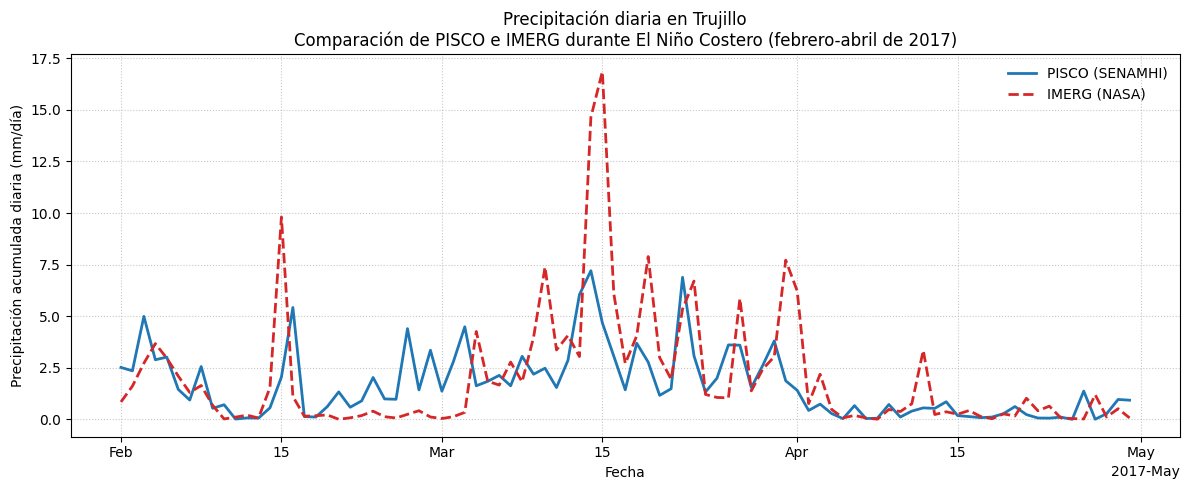

In [21]:
#Gráfico comparativo de la precipitación diaria
fig, ax = plt.subplots(figsize=(12, 5))

precip_pisco.plot( ax=ax, color='tab:blue', linewidth=2, label="PISCO (SENAMHI)")

precip_imerg.plot(ax=ax, color='tab:red', linewidth=2, linestyle='--', label="IMERG (NASA)")

ax.set_title( "Precipitación diaria en Trujillo\n" "Comparación de PISCO e IMERG durante El Niño Costero (febrero-abril de 2017)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precipitación acumulada diaria (mm/día)")
ax.legend(frameon=False)
ax.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()